In [4]:
import numpy as np # linear algebra
import struct
from array import array
from os.path  import join

class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath

    def read_images_labels(self, images_filepath, labels_filepath):
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())

        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img

        return images, labels

    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)



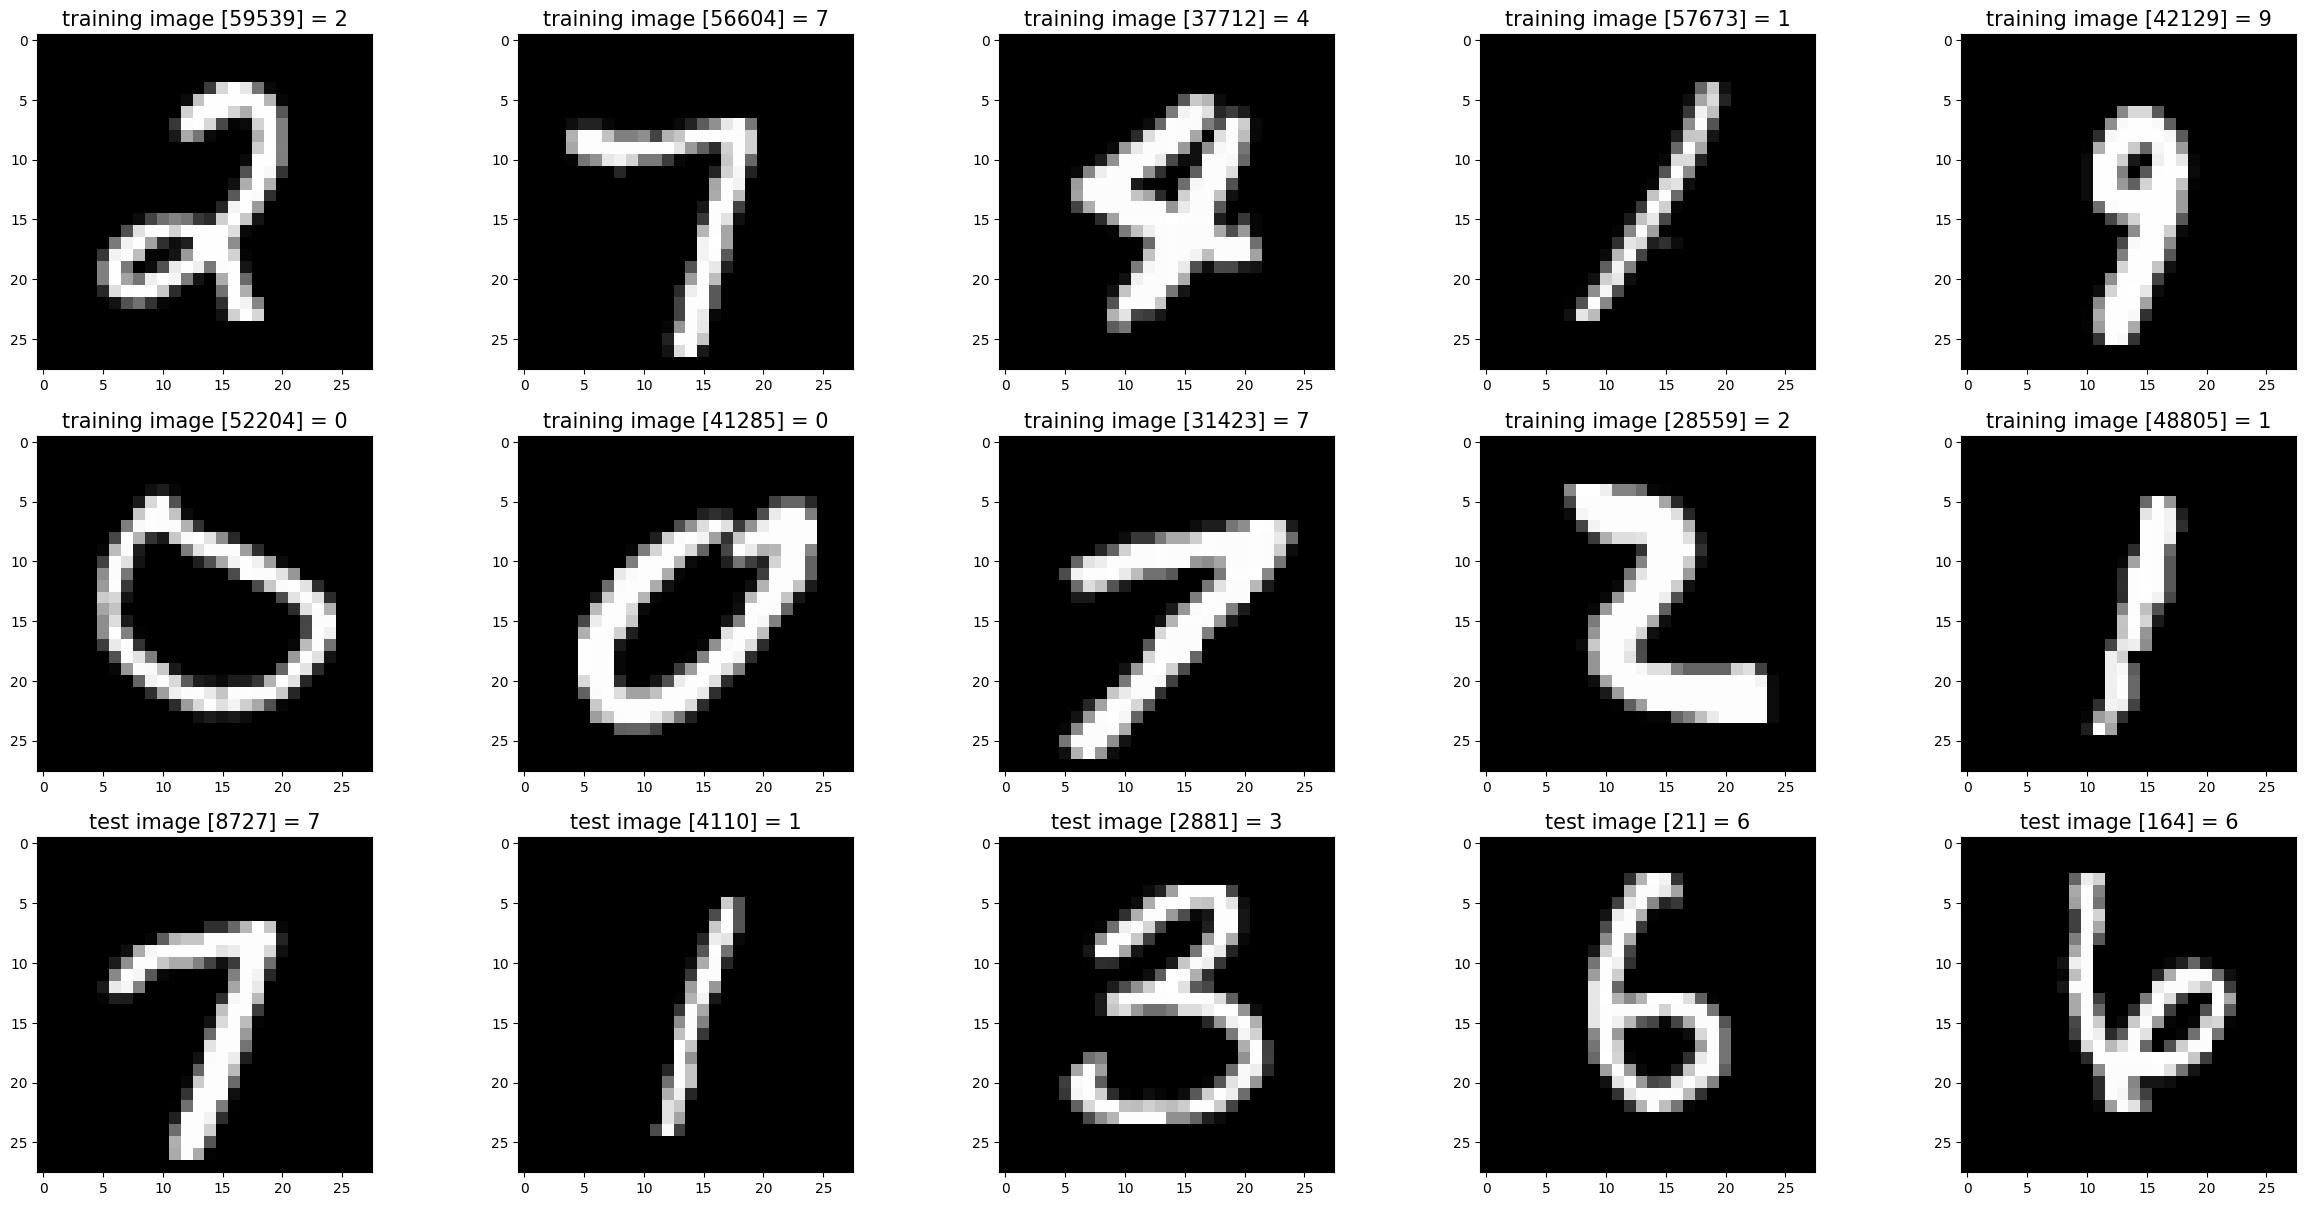

In [5]:
%matplotlib inline
import random
import matplotlib.pyplot as plt

training_images_filepath = '/content/train-images.idx3-ubyte'
training_labels_filepath = '/content/train-labels.idx1-ubyte'
test_images_filepath = '/content/t10k-images.idx3-ubyte'
test_labels_filepath = '/content/t10k-labels.idx1-ubyte'

def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1
    for x in zip(images, title_texts):
        image = x[0]
        title_text = x[1]
        plt.subplot(rows, cols, index)
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);
        index += 1

mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(0, len(x_train) - 1)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))

for i in range(0, 5):
    r = random.randint(0, len(x_test) - 1)
    images_2_show.append(x_test[r])
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))

show_images(images_2_show, titles_2_show)

In [6]:
import torch, torch.nn as nn, torch.nn.functional as F

def to_tensor(images, labels):
    x = torch.from_numpy(np.stack(images)).float().div(255.).unsqueeze(1)
    y = torch.tensor(list(labels), dtype=torch.long)
    return x, y

Xtr, ytr = to_tensor(x_train, y_train)
Xte, yte = to_tensor(x_test, y_test)

g = torch.Generator().manual_seed(0)
idx = torch.randperm(len(Xtr), generator=g)[:1000]
Xtr_s, ytr_s = Xtr[idx], ytr[idx]

model = nn.Sequential(nn.Flatten(1, -1), nn.Linear(784, 256), nn.ReLU(),
                      nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10))
opt = torch.optim.SGD(model.parameters(), lr=0.1)

def transform(x, angle_deg=0., tx=0.):
    a = torch.deg2rad(torch.tensor(angle_deg))
    theta = torch.tensor([[torch.cos(a), -torch.sin(a), tx],
                          [torch.sin(a),  torch.cos(a), 0.]]).expand(len(x), 2, 3)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, align_corners=False)

@torch.no_grad()
def evaluate(model, X, y, angles=(0, 10, 20, 30, 45)):
    model.eval()
    p0 = model(X).softmax(1)
    out = {}
    for a in angles:
        pa = model(transform(X, angle_deg=a)).softmax(1)
        out[a] = dict(acc=(pa.argmax(1) == y).float().mean().item(),
                      inv_err=(pa - p0).pow(2).sum(1).mean().item(),
                      consist=(pa.argmax(1) == p0.argmax(1)).float().mean().item())
    return out


evals = []
for epoch in range(50):
    model.train()
    perm = torch.randperm(len(Xtr_s))
    for i in range(0, len(perm), 64):
        b = perm[i:i+64]
        loss = F.cross_entropy(model(Xtr_s[b]), ytr_s[b])
        opt.zero_grad(); loss.backward(); opt.step()
    if epoch % 5 == 0:
        evals.append(evaluate(model, Xte[:2000], yte[:2000]))
        print(epoch, loss.item(), evals[-1])

0 2.2309951782226562 {0: {'acc': 0.36649999022483826, 'inv_err': 3.6434743708295425e-16, 'consist': 1.0}, 10: {'acc': 0.3504999876022339, 'inv_err': 3.628282138379291e-05, 'consist': 0.7854999899864197}, 20: {'acc': 0.304500013589859, 'inv_err': 8.871767204254866e-05, 'consist': 0.6330000162124634}, 30: {'acc': 0.2515000104904175, 'inv_err': 0.00013924222730565816, 'consist': 0.5044999718666077}, 45: {'acc': 0.19449999928474426, 'inv_err': 0.00020023137039970607, 'consist': 0.3889999985694885}}
5 0.6048205494880676 {0: {'acc': 0.7745000123977661, 'inv_err': 2.278511174224132e-14, 'consist': 1.0}, 10: {'acc': 0.737500011920929, 'inv_err': 0.02190147154033184, 'consist': 0.878000020980835}, 20: {'acc': 0.6225000023841858, 'inv_err': 0.09036333858966827, 'consist': 0.7179999947547913}, 30: {'acc': 0.44699999690055847, 'inv_err': 0.18735577166080475, 'consist': 0.5065000057220459}, 45: {'acc': 0.2639999985694885, 'inv_err': 0.31061649322509766, 'consist': 0.296999990940094}}
10 0.319576472

In [ ]:
evals[0][0]

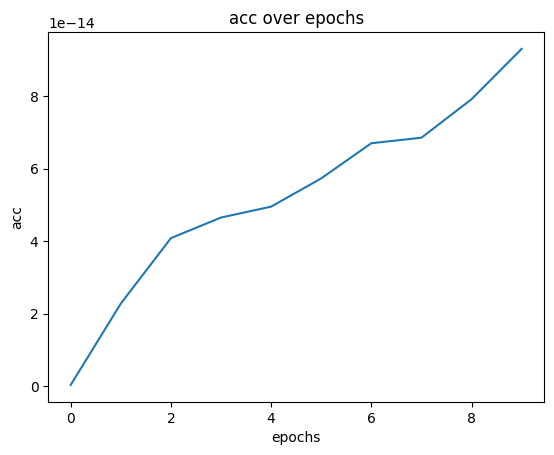

In [9]:
import matplotlib.pyplot as plt

# x = [x[0]['acc'] for x in evals]
inv_err = [x[0]['inv_err'] for x in evals]
# plt.plot(x)
plt.plot(inv_err)
plt.title("acc over epochs")
plt.xlabel("epochs")
plt.ylabel("acc")
plt.show()

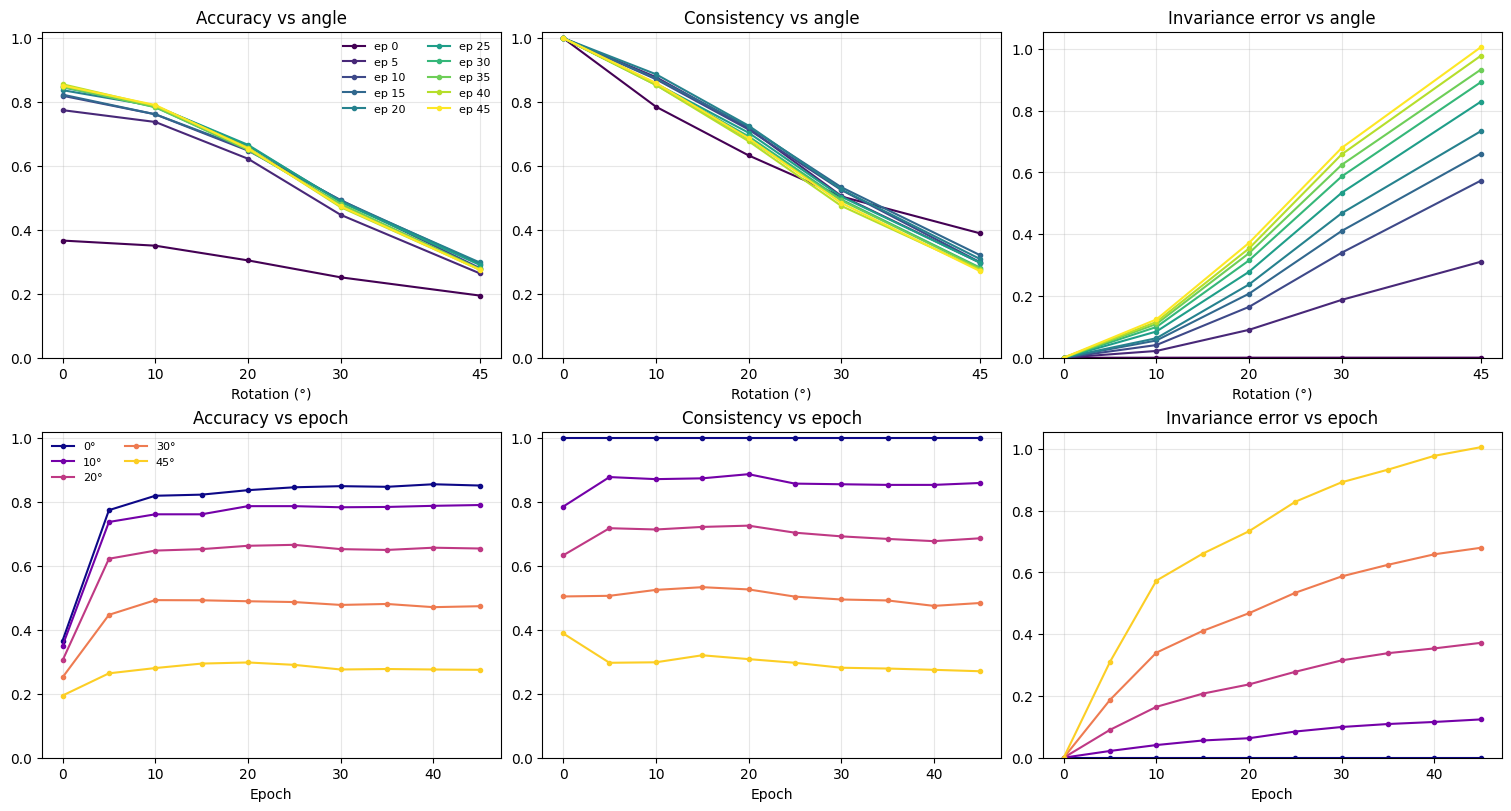

In [10]:
def plot_evals(evals, every=5):
    epochs = [i * every for i in range(len(evals))]
    angles = sorted(evals[0])
    panels = [("acc", "Accuracy", (0, 1.02)),
              ("consist", "Consistency", (0, 1.02)),
              ("inv_err", "Invariance error", (0, None))]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

    cm_ep = plt.cm.viridis(np.linspace(0, 1, len(evals)))
    for ax, (k, name, ylim) in zip(axes[0], panels):
        for ev, ep, c in zip(evals, epochs, cm_ep):
            ax.plot(angles, [ev[a][k] for a in angles], marker="o", ms=3, color=c, label=f"ep {ep}")
        ax.set(title=f"{name} vs angle", xlabel="Rotation (°)", ylim=ylim, xticks=angles)
        ax.grid(alpha=0.3)
    axes[0][0].legend(frameon=False, fontsize=8, ncol=2)

    cm_an = plt.cm.plasma(np.linspace(0, 0.9, len(angles)))
    for ax, (k, name, ylim) in zip(axes[1], panels):
        for a, c in zip(angles, cm_an):
            ax.plot(epochs, [ev[a][k] for ev in evals], marker="o", ms=3, color=c, label=f"{a}°")
        ax.set(title=f"{name} vs epoch", xlabel="Epoch", ylim=ylim)
        ax.grid(alpha=0.3)
    axes[1][0].legend(frameon=False, fontsize=8, ncol=2)

    plt.show()

plot_evals(evals)